# CHLA-Z methods 1: BGC-Argo retrieval and QC

**Author:** Eli Holmes (NOAA)<br>
Last updated: November 23, 2026

> **What this notebook is.** One of four *data methods* notebooks for the
> CHLA-Z tables in `datasets/chla_z/data/`. It shows, on a small real sample,
> exactly how BGC-Argo chlorophyll profiles are retrieved, quality controlled
> and binned. It is **not** about model training.
>
> **What it is not.** It does not build the tables. The full build runs from
> the command line, `datasets/chla_z/build.py`, which calls the same functions
> in `src/chla_z_build.py` that this notebook calls. The last section of the
> notebook checks that its result equals the released table.

| # | Notebook | Method | Build stage |
|---|---|---|---|
| 1 | **01-argo-retrieval-qc** | BGC-Argo retrieval, QC, depth bins | `argo` |
| 2 | 02-ooi-retrieval-qc | OOI retrieval, QC, 3 h solar-time windows, Sauzède correction | `ooi-fetch`, `ooi` |
| 3 | 03-pace-matchups | PACE Rrs, chlor_a, Kd matchups | `pace`, `pace-merge` |
| 4 | 04-olci-matchups | Sentinel-3 OLCI Rrs matchups | `olci`, `olci-merge` |

**The rules, in brief.** Data come from the Ifremer ERDDAP synthetic-BGC
dataset through `argopy` in *expert* mode, 2024-03-01 to 2026-10-31.

1. Keep ascending profiles only (`DIRECTION == "A"`).
2. Keep `CHLA_ADJUSTED` levels whose `CHLA_ADJUSTED_QC` is 1, 2, 5 or 8, *before*
   any averaging.
3. Average the kept levels in 10 m pressure bins from 0 to 200 dbar. A bin
   `CHLA_A_B` holds pressures in (A, B]: above A, up to and including B.
   `CHLA_A_B_N` counts the levels in it.
4. Drop profiles with no kept level in 0–200 dbar.

Runs in a few minutes; the only download is one 20° × 10° box for one month
(about 30 s).

In [1]:
import sys

if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")

import argopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from argopy import DataFetcher

import chla_z_build as b

argopy.__version__  # the build pins argopy==1.5.0 (requirements.txt)

'1.5.0'

## 1. Retrieve one region and month

`expert` mode returns every variable and every QC flag, including
`CHLA_ADJUSTED` and `CHLA_ADJUSTED_QC`; the default `standard` mode filters
for you, and we want to see and choose the filter. The source is the Ifremer
ERDDAP, not the GDAC; why is in `claude/notes/argo-gdac-vs-erddap.md`.

The region list is `[lon_min, lon_max, lat_min, lat_max, pres_min, pres_max,
start, end]`; the end date is exclusive. This box is the western North
Atlantic (Gulf Stream and Sargasso Sea), July 2025: a few floats here have
levels flagged bad, which makes it a useful example.

In [2]:
argopy.set_options(api_timeout=300)  # the ERDDAP server is slow under load

region = [-80, -60, 30, 40, 0, 200, "2025-07-01", "2025-08-01"]
fetcher = DataFetcher(ds="bgc", src="erddap", params=["CHLA", "PRES"],
                      mode="expert", cache=False)
ds = fetcher.region(region).to_xarray()
ds

<xarray.Dataset> Size: 2MB
Dimensions:                (N_POINTS: 8674)
Coordinates:
  * N_POINTS               (N_POINTS) int64 69kB 0 1 2 3 ... 8670 8671 8672 8673
    LATITUDE               (N_POINTS) float64 69kB 30.24 30.24 ... 34.98 34.98
    LONGITUDE              (N_POINTS) float64 69kB -75.16 -75.16 ... -63.77
    TIME                   (N_POINTS) datetime64[ns] 69kB 2025-07-02T04:31:54...
Data variables: (12/30)
    CHLA                   (N_POINTS) float32 35kB 0.07063 0.07254 ... 0.02146
    CHLA_ADJUSTED          (N_POINTS) float32 35kB 0.05216 0.05369 ... 0.001627
    CHLA_ADJUSTED_ERROR    (N_POINTS) float32 35kB 0.1043 0.1074 ... 0.003254
    CHLA_ADJUSTED_QC       (N_POINTS) int64 69kB 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1
    CHLA_DATA_MODE         (N_POINTS) <U1 35kB 'A' 'A' 'A' 'A' ... 'A' 'A' 'A'
    CHLA_QC                (N_POINTS) int64 69kB 3 3 3 3 3 3 3 ... 3 3 3 3 3 3 3
    ...                     ...
    TEMP_ADJUSTED          (N_POINTS) float32 35kB 28.25 28.25 ... 18.77 18.76
    TEMP_ADJUSTED_ERROR    (N_POINTS) float32 35kB 0.002 0.002 0.002 ... nan nan
    TEMP_ADJUSTED_QC       (N_POINTS) int64 69kB 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1
    TEMP_DATA_MODE         (N_POINTS) <U1 35kB 'D' 'D' 'D' 'D' ... 'A' 'A' 'A'
    TEMP_QC                (N_POINTS) int64 69kB 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1
    TIME_QC                (N_POINTS) int64 69kB 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1
Attributes:
    DATA_ID:              ARGO-BGC
    DOI:                  http://doi.org/10.17882/42182
    Fetched_from:         erddap.ifremer.fr
    Fetched_by:           jovyan
    Fetched_date:         2026/11/23
    Fetched_constraints:  [x=-80.00/-60.00; y=30.00/40.00; z=0.0/200.0; t=202...
    Fetched_uri:          https://erddap.ifremer.fr/erddap/tabledap/ArgoFloat...

Each row (`N_POINTS`) is one measurement: one level of one profile. A
profile is one `PLATFORM_NUMBER` (the float) and `CYCLE_NUMBER` (one dive and
ascent). These are the columns the build reads (`b.ARGO_VARS`):

In [3]:
df = ds[b.ARGO_VARS].to_dataframe().reset_index(drop=True)
print(len(df), "levels in",
      df.groupby(b.ARGO_KEY).ngroups, "profiles from",
      df["PLATFORM_NUMBER"].nunique(), "floats")
df.head()

8674 levels in 36 profiles from 13 floats


,PLATFORM_NUMBER,CYCLE_NUMBER,DIRECTION,TIME,LATITUDE,LONGITUDE,PRES,CHLA_ADJUSTED,CHLA_ADJUSTED_QC
0,6990687,14,A,2025-07-02 04:31:54,30.2421,-75.1625,4.3,0.052159,1
1,6990687,14,A,2025-07-02 04:31:54,30.2421,-75.1625,6.2,0.053692,1
2,6990687,14,A,2025-07-02 04:31:54,30.2421,-75.1625,8.0,0.056759,1
3,6990687,14,A,2025-07-02 04:31:54,30.2421,-75.1625,10.0,0.056759,1
4,6990687,14,A,2025-07-02 04:31:54,30.2421,-75.1625,12.0,0.052159,1


## 2. Quality control, step by step

**Direction.** Some floats also sample on the way down. The ascending
profile is the one most floats report and the one with a single time and
position, so descending profiles are dropped.

In [4]:
df["DIRECTION"].astype(str).str.strip().value_counts()

DIRECTION
A    8674
Name: count, dtype: int64

**QC flags.** `CHLA_ADJUSTED` is the adjusted chlorophyll: corrected for
the sensor's dark offset, for non-photochemical quenching near the surface,
and for the regional fluorescence:chla ratio (the same ratio the build
applies to OOI, notebook 2). Its flag says how far to trust each level ([Argo QC flag
table](https://argo.ucsd.edu/data/data-faq/)):

| flag | meaning | kept |
|---|---|---|
| 1 | good | yes |
| 2 | probably good | yes |
| 3 | probably bad, potentially correctable | no |
| 4 | bad | no |
| 5 | value changed | yes |
| 8 | estimated (interpolated) | yes |
| 0, 9 | no QC / missing | no |

The filter is applied to the levels *before* averaging, so a bad level never
pulls a bin mean. Most rejected levels are flag 9: pressure levels where the
float measured temperature and salinity but not chlorophyll. Their
`CHLA_ADJUSTED` is a fill value (99999 in a live fetch, NaN once saved to
netCDF and read back), which is one more reason to filter on the flag and
not on the value.

In [5]:
asc = df[df["DIRECTION"].astype(str).str.strip() == "A"]
real = asc["CHLA_ADJUSTED"].abs() < 1000  # not a fill value
pd.DataFrame({"levels": asc["CHLA_ADJUSTED_QC"].value_counts(),
              "with a CHLA value": asc[real]["CHLA_ADJUSTED_QC"].value_counts()}
             ).fillna(0).astype(int).sort_index().assign(
                 kept=lambda d: d.index.isin(b.QC_GOOD))

,levels,with a CHLA value,kept
CHLA_ADJUSTED_QC,,,
1,3476,3476,True
3,733,733,False
4,158,47,False
5,26,26,True
8,204,204,True
9,4077,0,False


**Depth bins.** Pressure in dbar is taken as metres (within about 1% in the
top 200 m). `b.bin_index_argo` gives the 0-based bin of each pressure, or
-1 outside (0, 200]. The edges matter: many floats report whole-number
pressures, and about 4% of Argo levels sit exactly on a 10 m edge. A level
at exactly 10 dbar is in the 0–10 bin, and one at exactly 0 is in no bin.

In [6]:
edges = np.array([0, 0.4, 10, 10.1, 20, 199.9, 200, 200.1])
pd.DataFrame({"PRES": edges, "bin": b.bin_index_argo(edges),
              "column": [b.CHLA_COLS[i] if i >= 0 else "(outside)"
                         for i in b.bin_index_argo(edges)]})

,PRES,bin,column
0,0.0,-1,(outside)
1,0.4,0,CHLA_0_10
2,10.0,0,CHLA_0_10
3,10.1,1,CHLA_10_20
4,20.0,1,CHLA_10_20
5,199.9,19,CHLA_190_200
6,200.0,19,CHLA_190_200
7,200.1,-1,(outside)


## 3. One profile, before and after

The dots are the levels of one ascending profile that have a CHLA value;
red ones are flagged 3 or 4 and dropped. The steps are the 10 m bin means
made from the black dots only.

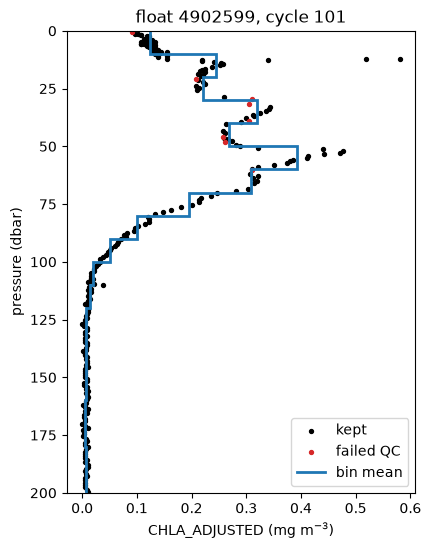

In [7]:
in_top = asc[asc["PRES"] <= 200]
flagged = in_top["CHLA_ADJUSTED_QC"].isin([3, 4]) & (in_top["CHLA_ADJUSTED"].abs() < 1000)
kept = in_top["CHLA_ADJUSTED_QC"].isin(b.QC_GOOD)
per_prof = pd.DataFrame({"flagged": flagged, "kept": kept}).groupby(
    [in_top[k] for k in b.ARGO_KEY]).sum()
# the profile with the most flagged levels among those that also have kept ones
key = per_prof[per_prof["kept"] > 0]["flagged"].idxmax()
one = asc[(asc["PLATFORM_NUMBER"] == key[0]) & (asc["CYCLE_NUMBER"] == key[1])]
one = one[one["CHLA_ADJUSTED"].abs() < 1000]
ok = one["CHLA_ADJUSTED_QC"].isin(b.QC_GOOD)

prof_one, _ = b.argo_bin_profiles(one)
means = prof_one[b.CHLA_COLS].iloc[0].to_numpy()

fig, ax = plt.subplots(figsize=(4.5, 6))
ax.scatter(one.loc[ok, "CHLA_ADJUSTED"], one.loc[ok, "PRES"], s=8, c="k", label="kept")
ax.scatter(one.loc[~ok, "CHLA_ADJUSTED"], one.loc[~ok, "PRES"], s=8, c="tab:red",
           label="failed QC")
ax.stairs(means, np.arange(0, 201, 10), orientation="horizontal", baseline=None,
          color="tab:blue", lw=2, label="bin mean")
ax.set_ylim(200, 0)
ax.set_xlabel("CHLA_ADJUSTED (mg m$^{-3}$)")
ax.set_ylabel("pressure (dbar)")
ax.set_title(f"float {key[0]}, cycle {key[1]}")
ax.legend(loc="lower right");

## 4. All profiles in the box

`b.argo_bin_profiles` does steps 1–4 for every profile at once and returns
one row per profile plus a count of what each step removed. The build calls
it once per month (`b.argo_month_unit`).

In [8]:
prof, stats = b.argo_bin_profiles(df)
stats

{'points': 8674,
 'profiles_all': 36,
 'profiles_descending': 0,
 'profiles_ascending': 36,
 'levels_ascending': 8674,
 'levels_good_qc': 3706,
 'profiles_with_good_chla': 27}

In [9]:
prof[["profile_id", "TIME", "LATITUDE", "LONGITUDE", "CHLA_0_10", "CHLA_0_10_N",
      "CHLA_10_20", "CHLA_10_20_N"]].head()

,profile_id,TIME,LATITUDE,LONGITUDE,CHLA_0_10,CHLA_0_10_N,CHLA_10_20,CHLA_10_20_N
0,3902334_0012,2025-07-10 19:27:14.002000128+00:00,36.592200,-61.845000,0.014995,5,0.022947,5
1,3902334_0013,2025-07-20 20:22:45.002000128+00:00,35.881000,-63.506300,0.038775,5,0.048848,5
2,3902334_0014,2025-07-30 21:41:55.002000128+00:00,34.975700,-63.772000,0.026520,5,0.026844,5
3,4902599_0100,2025-07-02 15:41:00+00:00,38.652351,-66.870178,0.031926,33,0.048047,14
4,4902599_0101,2025-07-12 10:44:00+00:00,37.940861,-68.593201,0.123105,43,0.244277,22


`profile_id` is `<platform, 7 digits>_<cycle, 4 digits>`. `TIME`, `LATITUDE`
and `LONGITUDE` are the profile's own; they do not vary within an ascending
profile. Positions flagged `POSITION_QC = 8` (interpolated, e.g. under ice)
are kept.

## 5. Check against the released table

Every profile from this box should be in `CHLA_argo_profiles.parquet` with
the same bin means.

In [10]:
released = pd.read_parquet(b.DATA_DIR / "CHLA_argo_profiles.parquet")
m = prof.merge(released, on="profile_id", suffixes=("", "_released"))
same = all(np.allclose(m[c], m[f"{c}_released"], equal_nan=True) for c in b.CHLA_COLS)
print(f"{len(prof)} profiles here, {len(m)} found in the released table; "
      f"all bin means equal: {same}")
assert len(m) == len(prof) and same

27 profiles here, 27 found in the released table; all bin means equal: True


A box fetched today can differ from the release if a float's data were
reprocessed after the release snapshot (ERDDAP, 2026-11-06). If the check
fails, that is the first thing to look at.

## Running the full build

The release used one netCDF file per month for the whole globe, made by
fetching 24 tiles of 60° longitude × 45° latitude per month in expert mode
and joining them (about 4 h; 7.8 GB in all). That fetch loop is in
`argopy.ipynb`, Workflow 2. The binning then runs from the command line,
one process per month, and resumes after a crash:

```
cd datasets/chla_z
python build.py argo --workers 3   # monthly .nc -> data/CHLA_argo_profiles.parquet
```

`chla_z_tables.write_argo_profiles()` writes the table and its parquet
metadata (sources, rules, code commit). Decisions behind the rules are in
`claude/notes/chla-z-rebuild-2026-11.md`.